### 1. Creación de un documento Google Colab

A. Crear un documento en Google Colab

Para la creación del archivo de Google Colab, al entrar en la herramienta se escoge la opción "Nuevo cuaderno" en la ventana emergente que genera directamente un archivo con formato .ipynp. Después, se renombra el archivo pinchando directamente en el nombre que sale por defecto y se modifica al escogido por el grupo.

B. Permitir que todos los integrantes del grupo tengan acceso a dicho documento

Para permitir que todos los integrantes del grupo tengan acceso a dicho documento, en el menú superior derecho se escoge la opción de compartir, se introducen los correos electrónicos de cada compañero y se asigna el rol de "Editor" a cada miembro del grupo para que todos tengan privilegios de lectura y modificación del código y texto del archivo. Finalmente se pulsa "Enviar" para que los compañeros reciban la notificación de acceso en sus bandejas de entrada del email y en la sección "Compartido conmigo" de cada uno de sus Google Drive.

### 2. Implementacion de algoritmos de aprendizaje automatico

A. Vectorizad la información sobre las clases de cada una de las muestras mediante One Hot Encoding

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Cargar dataset
iris = sns.load_dataset('iris')

# Variable objetivo
y = iris[['species']]

# One Hot Encoding
encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

print(y_encoded[:5])

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


B. Separad el conjunto de datos en dos grupos: uno de entrenamiento y otro de testeo. ¿Qué tanto por ciento de muestras creéis oportuno asignar a cada grupo?

Una distribucion habitual es 80% para entrenamiento y 20% para prueba. Permite disponer de suficientes datos para entrenar los modelos y mantiene una cantidad adecuada de muestras para evaluar su capacidad de generalización.

In [ ]:
from sklearn.model_selection import train_test_split

X = iris.drop('species', axis=1)
y = iris['species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Tamaño del conjunto de entrenamiento: {len(X_train)}")
print(f"Tamaño del conjunto de prueba: {len(X_test)}")

Tamaño del conjunto de entrenamiento: 120
Tamaño del conjunto de prueba: 30


C. Implementad y entrenad los algoritmos Support Vector Machines, Random Forrest y Naive Bayes para clasificar cada una de las muestras. Utilizad el grupo de testeo para comparar las predicciones de las clases para cada uno de estos algoritmos y calculad métricas como la Precisión, el Recall y el f1-score


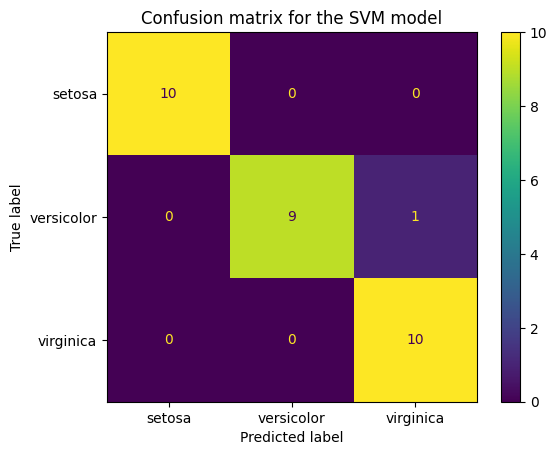

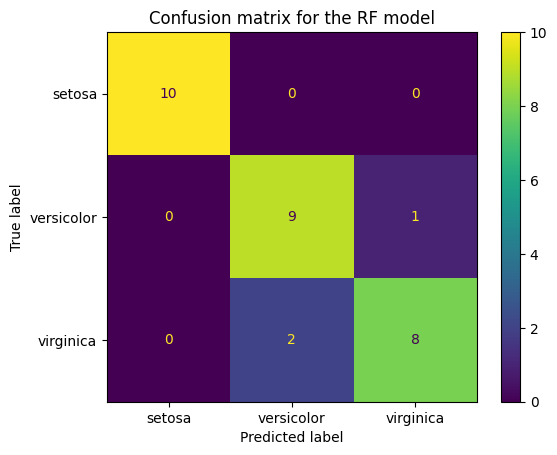

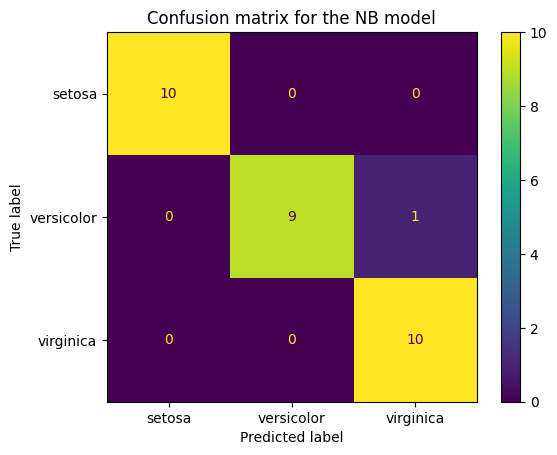

===== SVM =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

===== RANDOM FOREST =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

===== NAIVE BAYES =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virgin

In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Modelos
svm = SVC()
rf = RandomForestClassifier(random_state=42)
nb = GaussianNB()

# Entrenamiento
svm.fit(X_train, y_train)
rf.fit(X_train, y_train)
nb.fit(X_train, y_train)

# Predicciones
pred_svm = svm.predict(X_test)
pred_rf = rf.predict(X_test)
pred_nb = nb.predict(X_test)

# Matrices de confusión
# Support Vector Machine
svm.cm = confusion_matrix(y_test, pred_svm, labels=svm.classes_)
svm.cmDis = ConfusionMatrixDisplay(confusion_matrix=svm.cm, display_labels=svm.classes_)
svm.cmDis.plot()
plt.title('Confusion matrix for the SVM model')
plt.show()
# Random forest
rf.cm = confusion_matrix(y_test, pred_rf, labels=rf.classes_)
rf.cmDis = ConfusionMatrixDisplay(confusion_matrix=rf.cm, display_labels=rf.classes_)
rf.cmDis.plot()
plt.title('Confusion matrix for the RF model')
plt.show()
# Naive Bayes
nb.cm = confusion_matrix(y_test, pred_nb, labels=nb.classes_)
nb.cmDis = ConfusionMatrixDisplay(confusion_matrix=nb.cm, display_labels=nb.classes_)
nb.cmDis.plot()
plt.title('Confusion matrix for the NB model')
plt.show()

# Informe de estadísticas de predicción
print("===== SVM =====")
print(classification_report(y_test, pred_svm))

print("===== RANDOM FOREST =====")
print(classification_report(y_test, pred_rf))

print("===== NAIVE BAYES =====")
print(classification_report(y_test, pred_nb))

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

resultados = []

predicciones = {
    "SVM": pred_svm,
    "Random Forest": pred_rf,
    "Naive Bayes": pred_nb
}

for nombre_modelo, pred in predicciones.items():
    resultados.append({
        "Modelo": nombre_modelo,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro"),
        "Recall_macro": recall_score(y_test, pred, average="macro"),
        "F1_macro": f1_score(y_test, pred, average="macro")
    })

df_resultados = pd.DataFrame(resultados)
df_resultados

,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro
0,SVM,0.966667,0.969697,0.966667,0.966583
1,Random Forest,0.900000,0.902357,0.900000,0.899749
2,Naive Bayes,0.966667,0.969697,0.966667,0.966583


D. Justificad, en función a las métricas del apartado C, cuál es el mejor modelo. Si no hay un claro ganador, justificad entre aquellos modelos que tengan un rendimiento similar en qué situaciones sus predicciones serían más fiables.

Tras evaluar los tres algoritmos utilizando el conjunto de prueba, y como se observa en la tabla comparativa generada a partir de las métricas del apartado C, los modelos Support Vector Machine (SVM) y Naive Bayes obtienen el mejor rendimiento global, alcanzando una exactitud (accuracy) del 97 %, así como valores de precisión, recall y F1-score promedio de 0,97.

Por otro lado, el modelo Random Forest obtiene una exactitud del 90 % y métricas promedio de 0,90, mostrando un rendimiento inferior respecto a los otros dos algoritmos.

Al comparar SVM y Naive Bayes, ambos presentan exactamente las mismas métricas en este experimento. Los dos clasifican perfectamente la clase setosa y alcanzan valores muy altos para las clases versicolor y virginica. Por tanto, no existe un ganador claro basándose únicamente en las métricas obtenidas.

Sin embargo, si fuera necesario elegir uno de ellos, SVM sería la opción preferida, ya que está especialmente diseñado para encontrar fronteras de separación óptimas entre clases y suele ofrecer una gran capacidad de generalización en problemas de clasificación con conjuntos de datos pequeños y medianos como Iris. Además, suele ser más robusto cuando las clases presentan límites de decisión complejos.

Por su parte, Naive Bayes tiene la ventaja de ser computacionalmente más eficiente y rápido de entrenar, por lo que puede resultar más adecuado en escenarios con grandes volúmenes de datos o cuando se requiere una clasificación rápida. No obstante, este algoritmo asume independencia entre las variables de entrada, una hipótesis que no siempre se cumple en problemas reales.

En conclusión, los mejores resultados han sido obtenidos por SVM y Naive Bayes, ambos con un 97 % de precisión global. Debido a su mayor capacidad de generalización y menor dependencia de hipótesis simplificadoras sobre los datos, SVM puede considerarse el modelo más fiable para este problema concreto, aunque la diferencia práctica respecto a Naive Bayes es mínima.

# 3. Implementación de algoritmos de aprendizaje automático profundo



A. Preparación del Dataset y Preprocesamiento de Datos. Utiliza OpenCV para cargar y preprocesar el conjunto de imágenes

In [ ]:
# Importar librerías principales
import os
import zipfile
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models, Input

# Semillas de reproducibilidad
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Actv3_Python/Malaria Data.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

In [ ]:
# Se generan listas de imagenes y etiquetas
imagenes = []
etiquetas = []

carpetas = ['Parasitized', 'Uninfected']
for carpeta in carpetas:
    ruta_carpeta = os.path.join('Malaria', carpeta)  # Las subcarpetas estan dentro de otra llamada Malaria
    for archivo in os.listdir(ruta_carpeta):
        if archivo.endswith('.png'):
            ruta_img = os.path.join(ruta_carpeta, archivo)
            img = cv2.imread(ruta_img)
            img = cv2.resize(img, (32, 32))     # Reedimensión de imagenes a 32 x 32, valores más altos bloquean la RAM
            img = img / 255.0                   # Normalizar a [0,1]
            imagenes.append(img)
            if carpeta == 'Parasitized':
                etiquetas.append(1)  # Infectada
            else:
                etiquetas.append(0)  # Sana

# Convertimos a arrays de numpy
imagenes = np.array(imagenes, dtype=np.float32)
etiquetas = np.array(etiquetas)

print(f"Imágenes cargadas: {len(imagenes)}")

Imágenes cargadas: 27558


In [ ]:
# División del Dataset en entrenamiento (70%), validación (15%) y prueba (15%)

X_train, X_temp, y_train, y_temp = train_test_split(imagenes, etiquetas, test_size=0.3, random_state=SEED)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED)

print("Tamaños:", len(X_train), len(X_val), len(X_test))

Tamaños: 19290 4134 4134


B. Diseña una Red Neuronal Convolucional (CNN) utilizando TensorFlow/Keras

In [ ]:
### Diseño de la Red Neuronal Convolucional (CNN) utilizando TensorFlow/Keras ###

model = models.Sequential()
# input shape: especificar en primera capa las dimensiones de las imágenes 2D (alto, ancho, RGB)
model.add(Input(shape=(32,32,3)))
# Capa convolucional: escanea la imagen en cuadrantes más pequeños para buscar detalles
# Función de activación: ReLU (transforma los valores negativos en cero, retiene valores positivos, ideal para datos no lineales)
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))
# Capa de pooling: reduce los datos obtenidos de las imágenes para acelerar el análisis
model.add(layers.MaxPooling2D((2, 2)))
# Capa de dropout: descarta una proporción de neuronas para evitar overfitting
model.add(layers.Dropout(0.25))
# Repetimos el bucle convolutional-pooling-dropout otro par de veces, con variaciones en hiperparámetros
model.add(layers.Conv2D(64, (5, 5), activation='relu', padding='same')) # Usamos diferentes tamaños para escanear la imagen a distintas resoluciones
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.25))
model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Dropout(0.5))
# Agregar una capa de aplanamiento (flatten) para convertir la salida en vector
model.add(layers.Flatten())
# Agregar capas densas en la parte superior (es decir, al final de la red)
# Estas capas densas son buenas para realizar la clasificación entre variables categóricas binarias (Sana e Infectada)
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid')) # el 1 es porque la salida es binaria y activation sigmoid porque el rango de salida es de 0 y 1
# Mostrar arquitectura del modelo
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,217 (1004.75 KB)

 Trainable params: 257,217 (1004.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compilación del modelo de CNN
# Función de pérdida: Binary Cross Entropy, para salidas con variables binarias (en nuestro caso, Sana e Infectada)
model.compile(optimizer='adam',
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=['accuracy'])
# Entrenar el modelo (necesitamos tanto imágenes como etiquetas de entrenamiento, validación, y test)
history = model.fit(X_train,
                    y_train,
                    epochs=10,
                    batch_size=32,   # se pone tamaño batch en 32 para no bloquear la RAM
                    validation_data=(X_val, y_val))

Epoch 1/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 82s 132ms/step - accuracy: 0.7519 - loss: 0.4816 - val_accuracy: 0.9020 - val_loss: 0.2394
Epoch 2/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 78s 126ms/step - accuracy: 0.9168 - loss: 0.2176 - val_accuracy: 0.9320 - val_loss: 0.2063
Epoch 3/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 81s 125ms/step - accuracy: 0.9403 - loss: 0.1804 - val_accuracy: 0.9485 - val_loss: 0.1646
Epoch 4/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 83s 126ms/step - accuracy: 0.9463 - loss: 0.1656 - val_accuracy: 0.9509 - val_loss: 0.1556
Epoch 5/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 83s 127ms/step - accuracy: 0.9485 - loss: 0.1550 - val_accuracy: 0.9545 - val_loss: 0.1389
Epoch 6/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 82s 128ms/step - accuracy: 0.9497 - loss: 0.1482 - val_accuracy: 0.9538 - val_loss: 0.1368
Epoch 7/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 75s 124ms/step - accuracy: 0.9516 - loss: 0.1456 - val_accuracy: 0.9507 - val_loss: 0.1459
Epoch 8/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 87s 133ms/step - accuracy: 0.9529 - loss: 0

**•	¿Qué función de activación usarías en la última capa?**

Se utiliza la función de activación "sigmoid" en la última capa porque el problema consiste en una clasificación binaria (células infectadas o no infectadas). La función "sigmoid" devuelve valores entre 0 y 1 que pueden interpretarse como la probabilidad de pertenecer a la clase positiva (infectada). Además, es compatible con la función de pérdida binary_crossentropy, que es la más adecuada para problemas de clasificación binaria.

**•	¿Qué función de pérdida usarías?**

Se usa la función de pérdida "Binary Crossentropy" porque el problema consiste en una clasificación binaria (células infectadas y no infectadas). La salida del modelo se obtiene mediante una única neurona con activación sigmoid, que devuelve una probabilidad entre 0 y 1. La entropía cruzada binaria mide el error entre dicha probabilidad y la etiqueta real, siendo la función de pérdida estándar y más apropiada para este tipo de problemas.

**•	¿Cuántos canales ha escogido, y por qué?**

Se escogen 3 canales de entrada, ya que las imágenes se cargan en color, obteniendo imágenes de tamaño 32×32×3. Mantener los tres canales permite conservar la información cromática de las muestras microscópicas, lo que puede ayudar a la red neuronal a identificar patrones asociados a células infectadas y no infectadas. Por ello, la capa de entrada de la CNN se ha definido con input_shape=(32,32,3).

C. Generar gráficos que muestren la evolución de la función de pérdida y la precisión durante el entrenamiento, tanto en el conjunto de entrenamiento como en el de validación. Evalúa el modelo final en el conjunto de prueba y reporta métricas clave a través de una matriz de confusión. Además, presenta ejemplos de predicciones correctas e incorrectas junto con las imágenes correspondientes, para analizar y comprender los errores del modelo

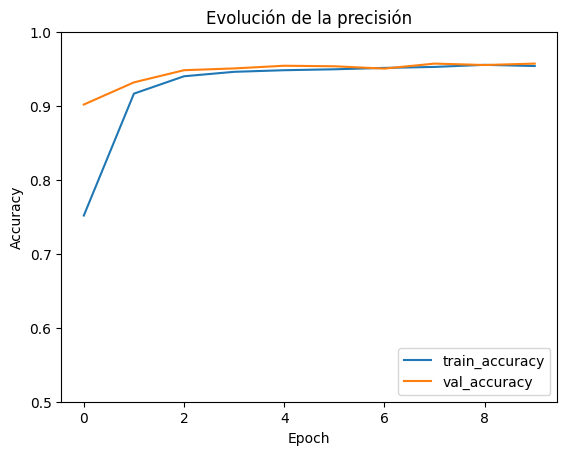

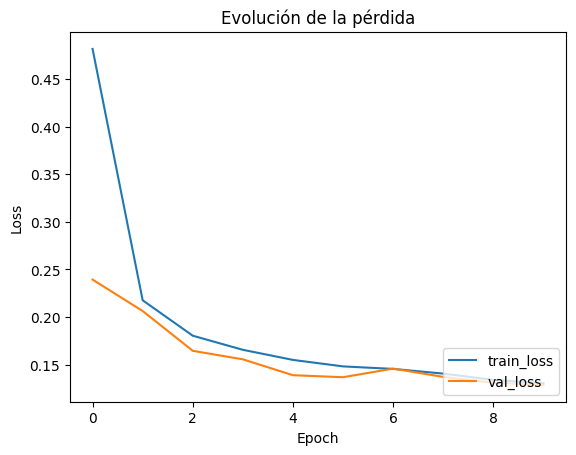

In [ ]:
# Generación de gráficos de la evolución de pérdida y precisión
import matplotlib.pyplot as plt

# Gráfico de precisión de entrenamiento y validación
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')

plt.title('Evolución de la precisión')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.show()

# Gráfico de pérdida de entrenamiento y validacion
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')

plt.title('Evolución de la pérdida')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='lower right')
plt.show()

In [ ]:
# Evaluación del modelo final en el conjunto de test
test_loss, test_acc = model.evaluate(X_test,  y_test, verbose=2)

print("Accuracy:", test_acc)
print("Loss:", test_loss)

130/130 - 3s - 26ms/step - accuracy: 0.9555 - loss: 0.1348
Accuracy: 0.9554910659790039
Loss: 0.13482896983623505


Reporte de métricas clave a través de una matriz de confusión:

Se evalúa el modelo mediante una matriz de confusión para analizar los aciertos y errores de clasificación en el conjunto de prueba. A partir de ella se obtienen métricas clave como precisión, recall y F1-score, fundamentales para evaluar el rendimiento del modelo.


130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step
Forma de y_test: (4134,)
Forma de y_pred: (4134,)
[[2032   47]
 [ 137 1918]]
              precision    recall  f1-score   support

  Uninfected       0.94      0.98      0.96      2079
 Parasitized       0.98      0.93      0.95      2055

    accuracy                           0.96      4134
   macro avg       0.96      0.96      0.96      4134
weighted avg       0.96      0.96      0.96      4134



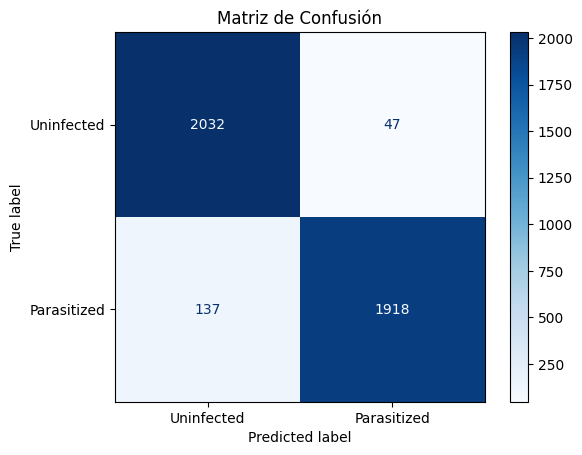

In [ ]:
import numpy as np

# Se obtienen las probabilidades predichas por el modelo
y_pred_prob = model.predict(X_test)

# Se transforman las probabilidades en clases binarias y se aplana el vector
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

# Nos aseguramos de que y_test también sea un vector plano
y_test = np.array(y_test).ravel()

print("Forma de y_test:", y_test.shape)
print("Forma de y_pred:", y_pred.shape)

# Se genera la matriz de confusión
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

# Obtención de métricas clave
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Uninfected', 'Parasitized']
))

# Visualización de la matriz
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Uninfected', 'Parasitized']
)

disp.plot(cmap='Blues')
plt.title("Matriz de Confusión")
plt.show()

A continuación se presentan ejemplos de predicciones correctas e incorrectas, junto con las imágenes correspondientes para muestras infectadas y sanas, para analizar y comprender los errores del modelo.


In [ ]:
####Recuento de celulas####

# Infectadas (1) correctamente clasificadas
infectadas_correctas = np.where(
    (y_test == 1) & (y_pred == 1)
)[0]

# Infectadas clasificadas incorrectamente
infectadas_incorrectas = np.where(
    (y_test == 1) & (y_pred == 0)
)[0]

# Sanas (0) correctamente clasificadas
sanas_correctas = np.where(
    (y_test == 0) & (y_pred == 0)
)[0]

# No infectadas clasificadas incorrectamente
sanas_incorrectas = np.where(
    (y_test == 0) & (y_pred == 1)
)[0]

print("Infectadas correctas:", len(infectadas_correctas))
print("Infectadas incorrectas:", len(infectadas_incorrectas))
print("Sanas correctas:", len(sanas_correctas))
print("Sanas incorrectas:", len(sanas_incorrectas))

print(
    "Total:",
    len(infectadas_correctas)
    + len(infectadas_incorrectas)
    + len(sanas_correctas)
    + len(sanas_incorrectas)
)

Infectadas correctas: 1918
Infectadas incorrectas: 137
Sanas correctas: 2032
Sanas incorrectas: 47
Total: 4134


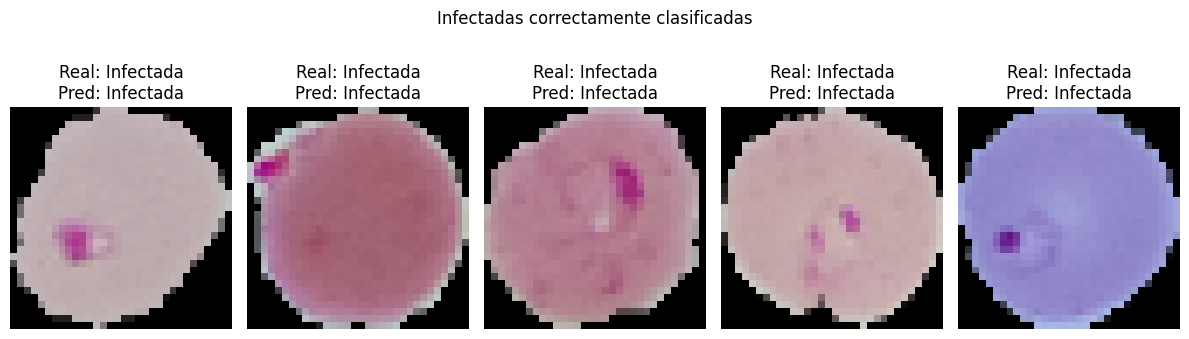

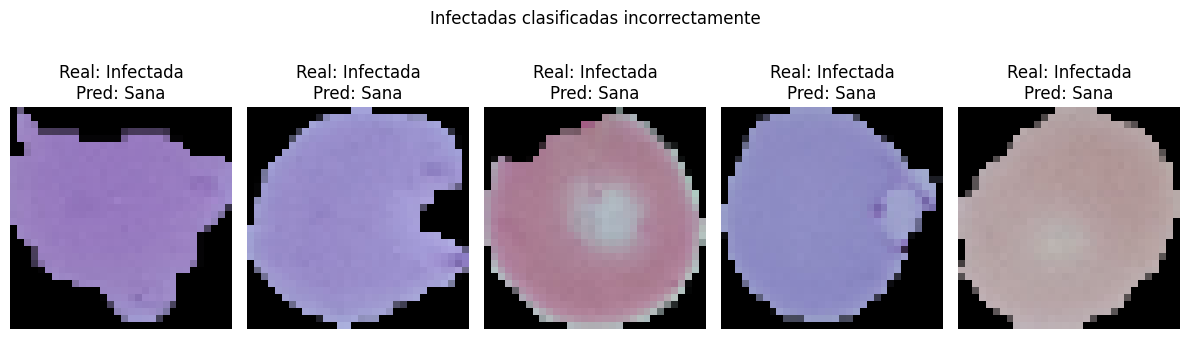

In [ ]:
####Infectadas correctas e incorrectas
plt.figure(figsize=(12,4))

for i, idx in enumerate(infectadas_correctas[:5]):
    plt.subplot(1,5,i+1)
    plt.imshow(X_test[idx])
    plt.axis('off')
    plt.title("Real: Infectada\nPred: Infectada")

plt.suptitle("Infectadas correctamente clasificadas")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(12,4))

for i, idx in enumerate(infectadas_incorrectas[:5]):
    plt.subplot(1,5,i+1)
    plt.imshow(X_test[idx])
    plt.axis('off')
    plt.title("Real: Infectada\nPred: Sana")

plt.suptitle("Infectadas clasificadas incorrectamente")
plt.tight_layout()
plt.show()
plt.close()

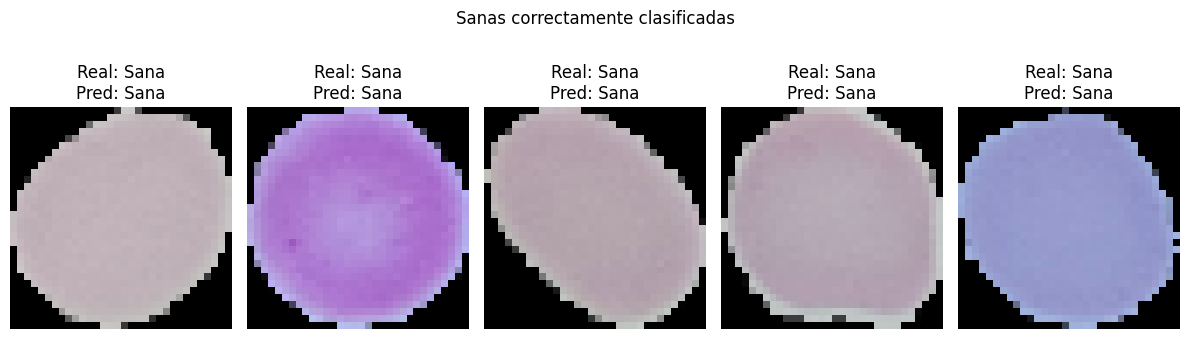

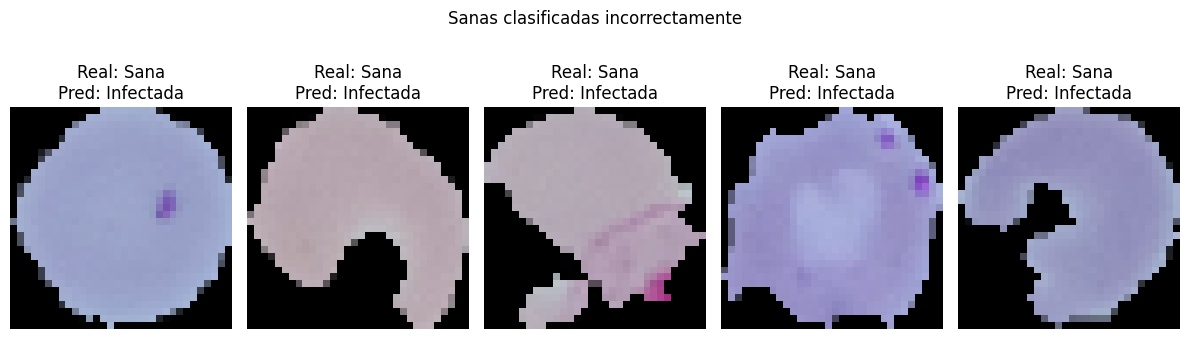

In [ ]:
###Sanas Correctas e Incorrectas
plt.figure(figsize=(12,4))

for i, idx in enumerate(sanas_correctas[:5]):
    plt.subplot(1,5,i+1)
    plt.imshow(X_test[idx])
    plt.axis('off')
    plt.title("Real: Sana\nPred: Sana")

plt.suptitle("Sanas correctamente clasificadas")
plt.tight_layout()
plt.show()
plt.close()

plt.figure(figsize=(12,4))

for i, idx in enumerate(sanas_incorrectas[:5]):
    plt.subplot(1,5,i+1)
    plt.imshow(X_test[idx])
    plt.axis('off')
    plt.title("Real: Sana\nPred: Infectada")

plt.suptitle("Sanas clasificadas incorrectamente")
plt.tight_layout()
plt.show()
plt.close()

Para interpretar correctamente las predicciones, las probabilidades generadas por la CNN se transformaron en clases binarias y se compararon con las etiquetas reales del conjunto de prueba. Los resultados muestran que el modelo clasifica correctamente 1909 células infectadas y 2035 células sanas, mientras que 146 células infectadas se clasifican como sanas y 44 células sanas como infectadas. En conjunto, estos valores reflejan un rendimiento elevado, con una accuracy aproximada del 95,4 %. Los ejemplos visuales ayudan a identificar que parte de los errores se producen en imágenes con rasgos celulares menos definidos o con tinciones menos evidentes.